<a href="https://colab.research.google.com/github/project-ccap/project-ccap.github.io/blob/master/2026notebooks/2026_1030_final_L6_colab_version.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2026_1030 版：6 カテゴリ条件付き尤度による当てはめ（「その他」はモデルの外）for 日本高次脳機能学会発表資料

**モデル**（2026-10-30 確定）

| 項目 | 設定 |
|---|---|
| ダイナミクス | 膜電位 $x(t)=x(t-1)(1-q)+\sum_i w_{ij}f(x_i(t-1))+\sigma\varepsilon$（加法ノイズのランジュバン方程式の Euler–Maruyama 近似），$q=0.6$，各段 $n=8$ |
| 出力関数 | $f(x)=[\tanh(x/2)]_+$（パラメータなし） |
| 結合 | 意味↔語彙 $s$，語彙↔音素 $p$（双方向） |
| 意味入力 | 標的 $k$ 特徴の膜電位 $=a/\sqrt{k}$（$a=13.2$，標的 1 特徴あたり 4.17） |
| 選択 | 膜電位の argmax（β=0）。$t=8$ で語彙層を one-hot（$J=1$）にして第 2 段階へ，$t=16$ で音素スロットごとに選択 |
| ネットワーク | Dell (1997) の 2 近傍を 90:10 で混合，文字列 → 6 カテゴリ |
| 無反応 | **モデル化しない。**「その他」（説明・無反応・雑多な反応，Dell 1997 Table 6 の All others）はモデルの外に置く |
| 尤度 | 6 カテゴリの条件付き多項尤度（Foygel & Dell 2000 と同じ扱い），$n=175$ |
| 単位 | σ を健常から決める（$s,\sigma$ を同時に $k$ 倍して当てはまりが崩れない範囲の上端 $\sigma_0$）。報告は $s/\sigma,\ p/\sigma$ と健常との比 |
| 推定 | 差分進化（2 シードの良い方，探索 $M=1000$），報告は $M=4000$ で再評価 |

**内容**：健常 → 21 症例（LH, IG を含む）と F&D (2000) SP モデルとの比較 → 回復実験 → 結論


Dell (1997) / Foygel & Dell (2000) SP モデルの「飽和型出力」版。

$$
\newcommand{\of}[1]{\left(#1\right)}
\newcommand{\Of}[1]{\left[#1\right]}
\newcommand{\OF}[1]{\left\{#1\right\}}
$$


確定仕様 (2026-10-29):
  * 各ノードは膜電位 x を持ち、出力は  
  $$
  y = \of{x} = \left[\tanh\of{\frac{x}{2}}\right]_{+}   = \left[2 \times \text{logistic}\of{x} - 1\right]_{+}.
  $$
    (パラメータなし、静止時 0、上限 1、負の膜電位では出力 0)
  * 更新:
$$
x\of{t} = x\of{t-1}\of{1-q} + \sum_{i} w_{ij} f\of{x_{i}\of{t-1}} + \sigma \times \epsilon,
$$

(加法ノイズのみ、SD2 なし)
          すなわち 加法ノイズのランジュバン方程式を $dt = 1$ でEuler-Maruyama 近似したもの
  * 結合: 意味<->語彙 $s$、語彙<->音素 $p$ (双方向・対称)、$q = 0.6$、各段 $n = 8$
  * 意味入力 ($t=0$ の意味特徴の膜電位):
        'unit' : 標的ベクトルを単位ノルムに正規化 (標的 10 特徴 = $1/\sqrt{10}$、他 0)  ← 主分析
        'z'    : 標的ベクトル (標的 1、他 0) を特徴全体で平均 0・分散 1 に標準化
        'norm' : 標的 k 特徴の膜電位 = $a/\sqrt{k}$、他 0。入力ベクトルのノルム = $a$ (F に依存しない) ← 採用
  * 選択は膜電位 x の argmax（select='x'，既定）。出力 $y=f\of{x}$ の argmax（旧版 select='y'）では，
    全ノードの出力が 0 のとき同点になり argmax が先頭（cat の音素）を返す誤りがあった（2026-10-30 修正）
  * $t=8$ : 語彙選択 = 6 語の argmax ($\beta= 0$)。語彙層の膜電位を one-hot (選ばれた語 = 1、他 0) にして
          第 2 段階を開始 (J = 1、意味入力の単位ノルムと同じ単位)
  * t=16: 頭子音・母音・尾子音ごとに argmax → 文字列 → カテゴリ
  * 無反応 (No_Resp ノードは廃止):
        'lex'  : t=8 で語彙層の最大出力 < theta なら無反応
        'phon' : t=16 で 3 スロットのうち最も弱いスロットの最大出力 < theta なら無反応
        'none' : 無反応を出さない（確定版。「その他」はモデルの外に置き，6 カテゴリの条件付き尤度で当てはめる）
  * 近傍 N1/N2 を 90:10 で混合、出力順: 正答, 意味, 形式, 混合, 無関連, 非単語, 無反応
  * 確率はモンテカルロ (共通乱数) の頻度。選択は決定論的なので推定は微分不要の手法で行う


In [1]:
# ===== モデル本体（dell_tanh.py と同一）=====
"""
Dell (1997) / Foygel & Dell (2000) SP モデルの「飽和型出力」版。

確定仕様 (2026-10-29):
  * 各ノードは膜電位 x を持ち、出力は y = f(x) = [tanh(x/2)]_+ = [2*logistic(x) - 1]_+
    (パラメータなし、静止時 0、上限 1、負の膜電位では出力 0)
  * 更新: x(t) = x(t-1)(1-q) + sum_i w_ij f(x_i(t-1)) + sigma * eps   (加法ノイズのみ、SD2 なし)
          = 加法ノイズのランジュバン方程式を dt=1 で Euler-Maruyama 近似したもの
  * 結合: 意味<->語彙 s、語彙<->音素 p (双方向・対称)、q = 0.6、各段 n = 8
  * 意味入力 (t=0 の意味特徴の膜電位):
        'unit' : 標的ベクトルを単位ノルムに正規化 (標的 10 特徴 = 1/sqrt(10)、他 0)  ← 主分析
        'z'    : 標的ベクトル (標的 1、他 0) を特徴全体で平均 0・分散 1 に標準化
        'norm' : 標的 k 特徴の膜電位 = a/sqrt(k)、他 0。入力ベクトルのノルム = a (F に依存しない) ← 採用
  * 選択は膜電位 x の argmax（select='x'，既定）。出力 y=f(x) の argmax（旧版 select='y'）では，
    全ノードの出力が 0 のとき同点になり argmax が先頭（cat の音素）を返す誤りがあった（2026-10-30 修正）
  * t=8 : 語彙選択 = 6 語の argmax (beta = 0)。語彙層の膜電位を one-hot (選ばれた語 = 1、他 0) にして
          第 2 段階を開始 (J = 1、意味入力の単位ノルムと同じ単位)
  * t=16: 頭子音・母音・尾子音ごとに argmax → 文字列 → カテゴリ
  * 無反応 (No_Resp ノードは廃止):
        'lex'  : t=8 で語彙層の最大出力 < theta なら無反応
        'phon' : t=16 で 3 スロットのうち最も弱いスロットの最大出力 < theta なら無反応
        'none' : 無反応を出さない（確定版。「その他」はモデルの外に置き，6 カテゴリの条件付き尤度で当てはめる）
  * 近傍 N1/N2 を 90:10 で混合、出力順: 正答, 意味, 形式, 混合, 無関連, 非単語, 無反応
  * 確率はモンテカルロ (共通乱数) の頻度。選択は決定論的なので推定は微分不要の手法で行う
"""
import itertools
import numpy as np
import torch

CATS = ['Correct', 'Semantic', 'Formal', 'Mixed', 'Unrelated', 'Nonword', 'No_Resp']
VOWELS, CODAS = ['ae', 'o'], ['t', 'g']
PHON = {'cat': ('k', 'ae', 't'), 'dog': ('d', 'o', 'g'), 'hat': ('h', 'ae', 't'),
        'mat': ('m', 'ae', 't'), 'rat': ('r', 'ae', 't'), 'log': ('l', 'o', 'g'),
        'fog': ('f', 'o', 'g')}
WORD_CAT = {'cat': 0, 'dog': 1, 'hat': 2, 'mat': 2, 'rat': 3, 'log': 4, 'fog': 4}
NEIGHBORHOODS = {
    1: dict(words=['cat', 'dog', 'hat', 'mat', 'log', 'fog'], onsets=['k', 'd', 'h', 'm', 'l', 'f']),
    2: dict(words=['cat', 'dog', 'mat', 'rat', 'log', 'fog'], onsets=['k', 'd', 'm', 'r', 'l', 'f']),
}
MIX = {1: 0.9, 2: 0.1}


def f_out(x):
    return torch.tanh(x / 2).clamp(min=0)


def build_network(nb, sem_input='unit', a=6.6):
    cfg = NEIGHBORHOODS[nb]
    words, onsets = cfg['words'], cfg['onsets']
    rows, nxt = [], 10
    for w in words:
        if w == 'cat':
            idx = list(range(10))
        elif w in ('dog', 'rat'):
            idx = [0, 1, 2] + list(range(nxt, nxt + 7)); nxt += 7
        else:
            idx = list(range(nxt, nxt + 10)); nxt += 10
        rows.append(idx)
    F = nxt
    S = np.zeros((6, F))
    for i, idx in enumerate(rows):
        S[i, idx] = 1.0
    P = np.zeros((6, 10))
    for i, w in enumerate(words):
        o, v, c = PHON[w]
        P[i, onsets.index(o)] = 1; P[i, 6 + VOWELS.index(v)] = 1; P[i, 8 + CODAS.index(c)] = 1
    v = np.zeros(F); v[:10] = 1.0
    if sem_input == 'unit':
        x0 = v / np.linalg.norm(v)
    elif sem_input == 'z':
        x0 = (v - v.mean()) / v.std()
    elif sem_input == 'norm':                 # 標的 k 特徴 = a/sqrt(k)、他 0（ノルム a、F に依存しない）
        x0 = v * (a / np.sqrt(v.sum()))
    else:
        raise ValueError(sem_input)
    word_of = {PHON[w]: w for w in words}
    scat = []
    for o, vv, c in itertools.product(onsets, VOWELS, CODAS):
        w = word_of.get((o, vv, c))
        scat.append(WORD_CAT[w] if w else 5)
    t = lambda a: torch.tensor(a, dtype=torch.float64)
    return dict(words=words, S=t(S), P=t(P), x0=t(x0), scat=torch.tensor(scat), F=F)


class DellTanh:
    def __init__(self, sem_input='unit', nr='lex', q=0.6, n=8, n_mc=2000, noise_seed=0, a=6.6, select='x'):
        self.q, self.n, self.nr, self.n_mc, self.sem_input = q, n, nr, n_mc, sem_input
        self.select = select   # 'x': 膜電位の argmax（Dell の「最も活性化したノード」，既定）／ 'y': 出力の argmax（旧版）
        self.nets = {nb: build_network(nb, sem_input, a) for nb in (1, 2)}
        g = torch.Generator().manual_seed(noise_seed)
        self.eps = {nb: [torch.randn(2 * n, n_mc, k, generator=g, dtype=torch.float64)
                         for k in (net['S'].shape[1], 6, 10)] for nb, net in self.nets.items()}

    @torch.no_grad()
    def run_nb(self, s, p, sig, theta, nb):
        net, (es, el, ep) = self.nets[nb], self.eps[nb]
        S, P = net['S'], net['P']
        B, M = s.shape[0], self.n_mc
        s3, p3, g3, th = s.view(B, 1, 1), p.view(B, 1, 1), sig.view(B, 1, 1), theta.view(B, 1)
        d = 1.0 - self.q
        xs = net['x0'].expand(B, M, -1).clone()
        xl = torch.zeros(B, M, 6, dtype=torch.float64)
        xp = torch.zeros(B, M, 10, dtype=torch.float64)

        def step(xs, xl, xp, t):
            ys, yl, yp = f_out(xs), f_out(xl), f_out(xp)
            ns = xs * d + s3 * (yl @ S) + g3 * es[t]
            nl = xl * d + s3 * (ys @ S.T) + p3 * (yp @ P.T) + g3 * el[t]
            npp = xp * d + p3 * (yl @ P) + g3 * ep[t]
            return ns, nl, npp

        for t in range(self.n):
            xs, xl, xp = step(xs, xl, xp, t)
        yl = f_out(xl)
        sel = (xl if self.select == 'x' else yl).argmax(-1)   # (B, M)
        nr = torch.zeros(B, M, dtype=torch.bool)
        if self.nr == 'lex':
            nr = yl.max(-1).values < th
        xl = torch.nn.functional.one_hot(sel, 6).to(torch.float64)   # J = 1
        for t in range(self.n, 2 * self.n):
            xs, xl, xp = step(xs, xl, xp, t)
        yp = f_out(xp)
        zp = xp if self.select == 'x' else yp
        o, v, c = zp[..., :6].argmax(-1), zp[..., 6:8].argmax(-1), zp[..., 8:].argmax(-1)
        if self.nr == 'phon':
            weakest = torch.stack([yp[..., :6].max(-1).values, yp[..., 6:8].max(-1).values,
                                   yp[..., 8:].max(-1).values], -1).min(-1).values
            nr = weakest < th
        cat = net['scat'][o * 4 + v * 2 + c]
        cat = torch.where(nr, torch.full_like(cat, 6), cat)
        return torch.nn.functional.one_hot(cat, 7).to(torch.float64).mean(1)   # (B, 7)

    def predict(self, s, p, sig, theta):
        a = [np.atleast_1d(np.asarray(x, float)) for x in (s, p, sig, theta)]
        a = np.broadcast_arrays(*a)
        out = []
        for k in range(0, len(a[0]), 50):
            tt = [torch.tensor(np.ascontiguousarray(x[k:k + 50])) for x in a]
            out.append(sum(w * self.run_nb(*tt, nb) for nb, w in MIX.items()).numpy())
        return np.vstack(out)


def to_model_order(row):
    """論文の列順 (C,S,F,N,M,U) -> モデル順 (C,S,F,M,U,N) + 無反応 (残差)。総和 > 1 は再正規化。"""
    c, s_, f_, n_, m_, u_ = row
    v = np.array([c, s_, f_, m_, u_, n_], float); tot = v.sum()
    return np.append(v / tot, 0.0) if tot > 1 else np.append(v, 1 - tot)


CONTROL_TABLE = [0.969, 0.012, 0.001, 0.000, 0.009, 0.003]
LH_TABLE = [0.69, 0.03, 0.07, 0.15, 0.01, 0.02]
IG_TABLE = [0.69, 0.09, 0.05, 0.02, 0.03, 0.01]


In [2]:
import time, numpy as np, torch, matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
from scipy.stats import chi2, spearmanr
from matplotlib import font_manager

# 図中に日本語を表示するため
try:
    import matplotlib_fontja
except ImportError:
    !pip install matplotlib-fontja
    import matplotlib_fontja

torch.set_num_threads(2)
np.set_printoptions(suppress=True, linewidth=160)

N = 175  # Philadelphia Naming Test の図版枚数

# F&D (2000) Table 4：患者データ（C,S,F,N,M,U）, S-F 予測（C,S,F,N,M,U）, s, f
FD = {
 'W.B.':  ([.94,.02,.01,.01,.01,.00], [.9419,.0282,.0076,.0172,.0047,.0004], .0352,.0274),
 'T.T.':  ([.93,.01,.01,.00,.02,.00], [.9689,.0077,.0109,.0000,.0125,.0000], .0340,.0866),
 'J.Fr.': ([.92,.01,.01,.02,.02,.00], [.9332,.0366,.0074,.0140,.0070,.0018], .0316,.0305),
 'V.C.':  ([.87,.02,.01,.03,.01,.00], [.9317,.0246,.0079,.0305,.0053,.0000], .0407,.0229),
 'L.B.':  ([.82,.04,.02,.09,.01,.01], [.8213,.0534,.0273,.0828,.0075,.0077], .0274,.0221),
 'J.B.':  ([.76,.06,.01,.05,.02,.01], [.8419,.0564,.0259,.0561,.0084,.0113], .0264,.0246),
 'J.L.':  ([.76,.03,.01,.06,.03,.01], [.7921,.0601,.0375,.0867,.0107,.0129], .0255,.0221),
 'G.S.':  ([.70,.02,.06,.15,.01,.02], [.7182,.0555,.0505,.1511,.0080,.0167], .0246,.0191),
 'L.H.':  ([.69,.03,.07,.15,.01,.02], [.6712,.0573,.0661,.1768,.0085,.0201], .0237,.0178),
 'J.G.':  ([.55,.06,.08,.18,.04,.03], [.5667,.0746,.0882,.2170,.0123,.0412], .0191,.0172),
 'E.G.':  ([.93,.03,.00,.01,.02,.00], [.9332,.0336,.0074,.0140,.0070,.0018], .0316,.0305),
 'B.Me.': ([.84,.03,.01,.00,.05,.01], [.8468,.0313,.0938,.0000,.0177,.0104], .0165,.0866),
 'B.Mi.': ([.83,.05,.01,.01,.02,.01], [.8973,.0538,.0181,.0128,.0078,.0102], .0255,.0328),
 'J.A.':  ([.78,.04,.00,.02,.03,.01], [.8627,.0637,.0263,.0236,.0093,.0144], .0246,.0294),
 'A.F.':  ([.75,.02,.03,.07,.06,.04], [.7113,.0841,.0644,.0935,.0123,.0344], .0205,.0229),
 'N.C.':  ([.75,.03,.07,.08,.01,.00], [.7693,.0638,.0479,.0907,.0082,.0201], .0237,.0221),
 'I.G.':  ([.69,.09,.05,.02,.03,.01], [.7948,.0863,.0544,.0131,.0138,.0376], .0198,.0340),
 'H.B.':  ([.61,.06,.13,.18,.02,.01], [.5667,.0746,.0882,.2170,.0123,.0412], .0191,.0172),
 'J.F.':  ([.56,.14,.01,.02,.11,.01], [.5237,.1369,.1662,.0136,.0178,.1418], .0107,.0365),
 'G.L.':  ([.28,.04,.21,.30,.03,.09], [.2716,.1020,.1565,.3230,.0137,.1332], .0093,.0154),
 'W.R.':  ([.08,.06,.15,.28,.05,.33], [.1343,.1179,.2319,.2594,.0132,.2433], .0010,.0178),
}
# Dell (1997) Table 5：失語型，聴覚的理解（BDAE パーセンタイル）
CLIN = {'J.A.':('超皮質性感覚',58),'J.B.':('伝導',85),'L.B.':('失名辞',87),'H.B.':('伝導',81),'V.C.':('失名辞',83),'N.C.':('伝導',35),
        'J.F.':('失名辞',69),'A.F.':('ウェルニッケ',35),'J.Fr.':('ウェルニッケ',73),'E.G.':('失名辞',86),'I.G.':('失名辞',70),'J.G.':('伝導',83),
        'L.H.':('伝導',89),'J.L.':('伝導',86),'G.L.':('ウェルニッケ',70),'B.Me.':('失名辞',78),'B.Mi.':('失名辞',90),'W.R.':('ウェルニッケ',29),
        'G.S.':('ウェルニッケ',36),'T.T.':('失名辞',83),'W.B.':('ウェルニッケ',46)}
PATS = list(FD)
DATA = {k: to_model_order(v[0]) for k, v in FD.items()}
CTRL = to_model_order(CONTROL_TABLE)
def fd_pred(name):   # F&D 予測をモデル順（無反応なし）
    c, s_, f_, n_, m_, u_ = FD[name][1]; return np.array([c, s_, f_, m_, u_, n_])
NAMES = ['s', 'p', 'sig', 'theta']
BND = dict(s=(1e-4, 1.0), p=(1e-4, 1.0), sig=(1e-5, 1.0), theta=(1e-6, 1.0), a=(0.5, 60.0))

def counts(obs): return np.asarray(obs, float) / np.sum(obs) * N
def G2_7(pr, c):
    e = np.maximum(pr, 1e-12) * c.sum(); k = c > 0
    return 2 * (c[k] * np.log(c[k] / e[k])).sum()
def G2_6(pr6, c):
    c6 = c[:6]; q = np.maximum(np.asarray(pr6)[:6], 1e-12); e = q / q.sum() * c6.sum(); k = c6 > 0
    return 2 * (c6[k] * np.log(c6[k] / e[k])).sum()
def pred(m, th): return m.predict(th['s'], th['p'], th['sig'], th['theta'])

def de_fit(m, c, free, fixed, maxiter=40, popsize=10, seed=0):
    # 6 カテゴリの条件付き尤度（G2_6）を最小化
    lo = np.log([BND[k][0] for k in free]); hi = np.log([BND[k][1] for k in free])
    def obj(X):
        th = {k: np.full(X.shape[1], v) for k, v in fixed.items()}
        for i, k in enumerate(free): th[k] = np.exp(X[i])
        return np.array([G2_6(p_, c) for p_ in pred(m, th)])
    r = differential_evolution(obj, list(zip(lo, hi)), vectorized=True, updating='deferred', polish=False,
                               maxiter=maxiter, popsize=popsize, seed=seed, tol=1e-8, init='sobol')
    th = dict(fixed); th.update({k: float(np.exp(v)) for k, v in zip(free, r.x)})
    return {k: float(th[k]) for k in NAMES}, float(r.fun)

A = 4.17 * np.sqrt(10)                                        # 標的 1 特徴あたり 4.17
mS = DellTanh('norm', 'none', n_mc=1000, noise_seed=0, a=A)   # 探索
mE = DellTanh('norm', 'none', n_mc=4000, noise_seed=0, a=A)   # 報告
TH0 = 0.0                                                     # 無反応なし（θ は使わない）
SEEDS = [0, 1]
def fit2(m, c, free, fixed, maxiter=30, popsize=8):
    cand = [de_fit(m, c, free, fixed, maxiter=maxiter, popsize=popsize, seed=sd) for sd in SEEDS]
    return min(cand, key=lambda z: z[1])
def norm6(v): v = np.asarray(v, float)[:6]; return v / v.sum()
print(f'{len(PATS)} 症例を読み込んだ。')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 18.6 MB/s  0:00:00
21 症例を読み込んだ。


## 1. 健常

In [3]:
cC = counts(CTRL)
J, _ = fit2(mS, cC, ['s', 'p', 'sig'], {'theta': TH0}, maxiter=40, popsize=12)
ks = np.geomspace(1/10, 10, 13)
gk = np.array([G2_6(x, cC) for x in pred(mE, dict(s=J['s']*ks, p=np.full(13, J['p']), sig=J['sig']*ks, theta=np.full(13, TH0)))])
SIG0 = J['sig'] * ks[np.where(gk <= gk.min() + 1.0)[0].max()]
print('(s,σ) を k 倍したときの G2(6): ' + ' '.join(f'{k_:.2g}:{g_:.1f}' for k_, g_ in zip(ks, gk)))
H, _ = fit2(mS, cC, ['s', 'p'], {'sig': SIG0, 'theta': TH0}, maxiter=40, popsize=12)
prH = pred(mE, H)[0]
print(f"σ0 = {SIG0:.3g}   健常: s/σ = {H['s']/SIG0:.2f}  p/σ = {H['p']/SIG0:.1f}  G2(6) = {G2_6(prH, cC):.2f}（自由度 3）")
print('6 カテゴリ（正答, 意味, 形式, 混合, 無関連, 非単語）')
print('  データ:', np.round(norm6(CTRL), 3)); print('  予測  :', np.round(norm6(prH), 3))


(s,σ) を k 倍したときの G2(6): 0.1:2.7 0.15:2.7 0.22:2.7 0.32:2.7 0.46:2.7 0.68:2.7 1:2.7 1.5:2.7 2.2:2.7 3.2:6.6 4.6:40.4 6.8:138.1 10:287.8
σ0 = 0.000124   健常: s/σ = 15.48  p/σ = 783.4  G2(6) = 2.69（自由度 3）
6 カテゴリ（正答, 意味, 形式, 混合, 無関連, 非単語）
  データ: [0.975 0.012 0.001 0.009 0.003 0.   ]
  予測  : [0.976 0.013 0.006 0.003 0.002 0.   ]


## 2. 21 症例と F&D (2000) SP モデルとの比較

In [ ]:
%%time
P = {}
t0 = time.time()
for nm in PATS:
    c = counts(DATA[nm]); th, _ = fit2(mS, c, ['s', 'p'], {'sig': SIG0, 'theta': TH0})
    pr = pred(mE, th)[0]; P[nm] = dict(th=th, pr=pr, G2=G2_6(pr, c), G2fd=G2_6(fd_pred(nm), c))
print(f'({time.time()-t0:.0f}s)\n')
print(f"{'症例':>6s} {'失語型':>8s} | {'s/σ':>6s} {'p/σ':>7s} | {'s×健常':>7s} {'p×健常':>7s} {'p/s×健常':>8s} | {'本モデル G2(6)':>13s} {'F&D G2(6)':>9s} | 「その他」")
for nm in PATS:
    r = P[nm]; th = r['th']
    print(f"{nm:>6s} {CLIN[nm][0]:>8s} | {th['s']/SIG0:6.2f} {th['p']/SIG0:7.1f} | {th['s']/H['s']:7.2f} {th['p']/H['p']:7.2f} {(th['p']/th['s'])/(H['p']/H['s']):8.2f} | "
          f"{r['G2']:13.1f} {r['G2fd']:9.1f} | {DATA[nm][6]:.2f}")
gm = np.array([P[n]['G2'] for n in PATS]); gf = np.array([P[n]['G2fd'] for n in PATS])
iw = PATS.index('W.R.')
print(f"\nG2(6) 合計：提案モデル {gm.sum():.1f}，F&D {gf.sum():.1f}（W.R. を除くと {gm.sum()-gm[iw]:.1f} 対 {gf.sum()-gf[iw]:.1f}）")
print(f"中央値：本モデル {np.median(gm):.1f}，F&D {np.median(gf):.1f}；提案モデルが良い症例 {(gm < gf).sum()}/21")
print(f"自由度 3 の 5% 臨界値 7.81 以内の症例：提案モデル {(gm <= 7.81).sum()}/21，F&D {(gf <= 7.81).sum()}/21")
sv = np.array([P[n]['th']['s']/H['s'] for n in PATS]); pv_ = np.array([P[n]['th']['p']/H['p'] for n in PATS])
print(f"順位相関：s（×健常）と F&D の s ρ = {spearmanr(sv, [FD[n][2] for n in PATS])[0]:+.2f}；p（×健常）と F&D の f ρ = {spearmanr(pv_, [FD[n][3] for n in PATS])[0]:+.2f}")
for t in ['伝導', 'ウェルニッケ', '失名辞']:
    idx = [i for i, n in enumerate(PATS) if CLIN[n][0] == t]
    print(f"  {t:>6s}（{len(idx)} 例）: s 中央値 {np.median(sv[idx]):.2f}，p 中央値 {np.median(pv_[idx]):.2f}，p/s 中央値 {np.median(pv_[idx]/sv[idx]):.2f}（×健常）")


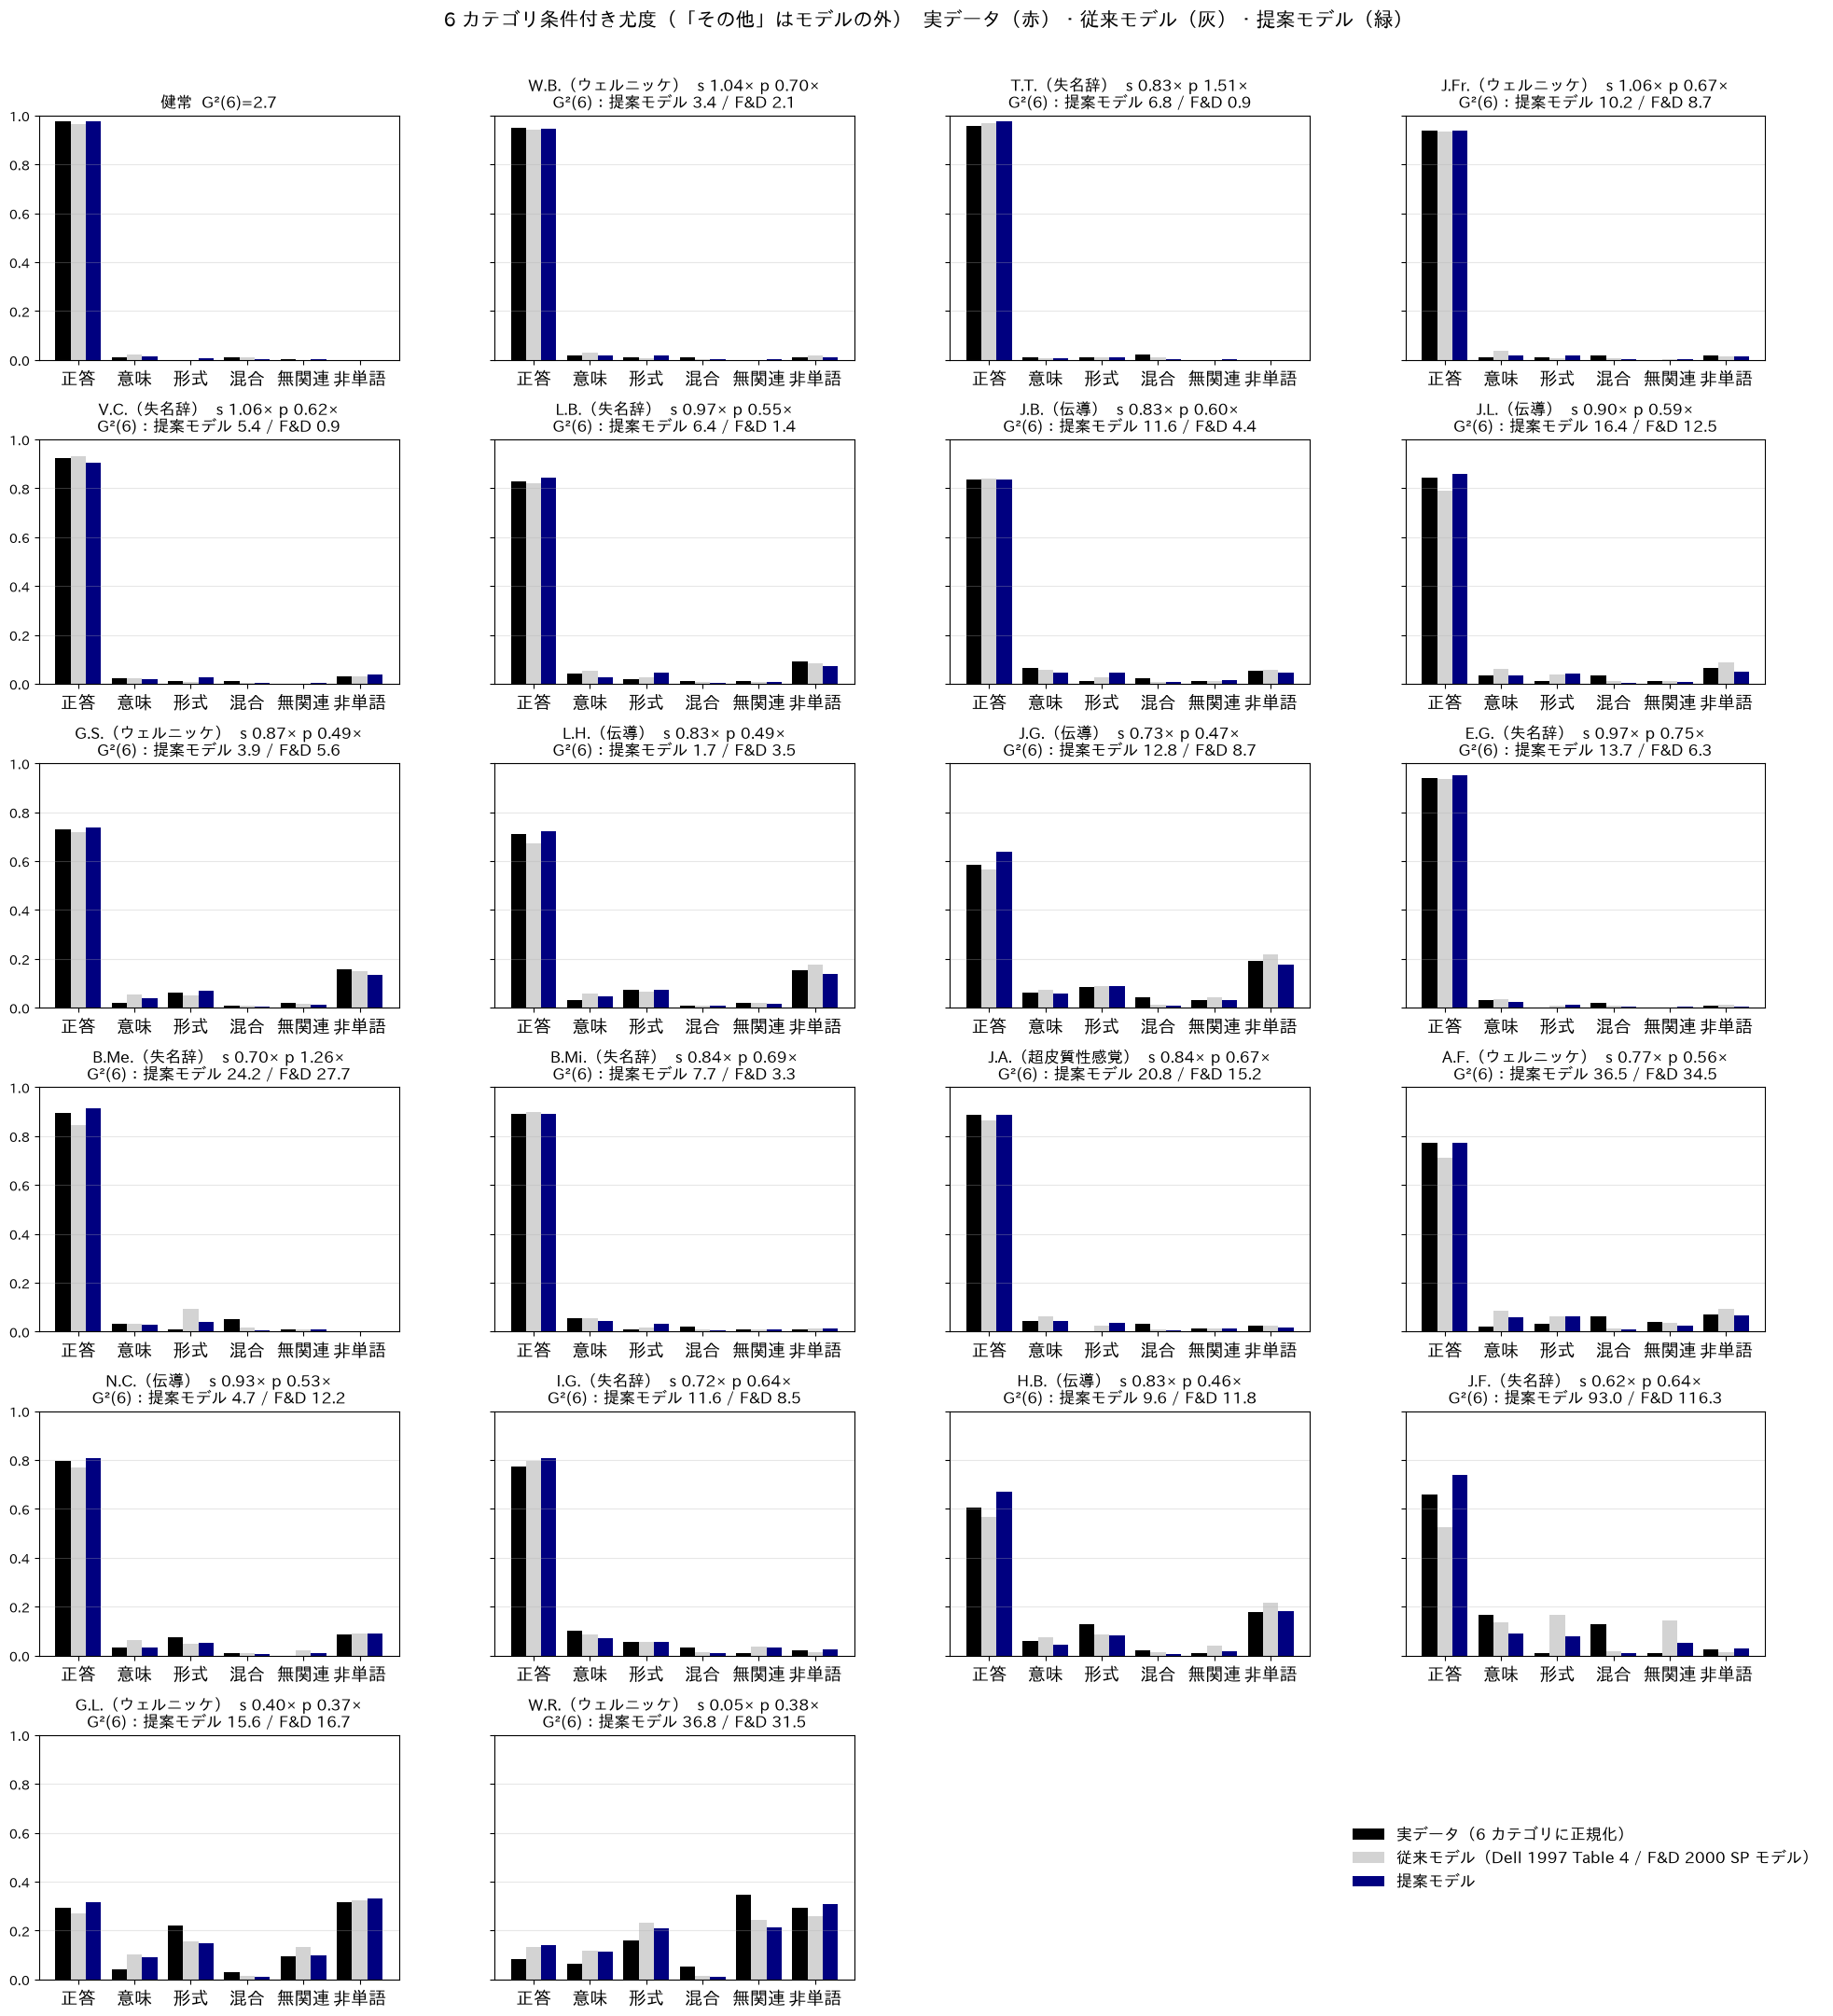

In [ ]:
CATJ = ['正答','意味','形式','混合','無関連','非単語']
cols = {'伝導': '#1f77b4', '失名辞': '#d62728', 'ウェルニッケ': '#2ca02c', '超皮質性感覚': '#9467bd'}

# 図 1：棒グラフ（健常 + 21 症例）
order = ['control'] + PATS
fig, axes = plt.subplots(6, 4, figsize=(20, 22), sharey=True)

x = np.arange(6)
w = 0.27
for a_, nm in zip(axes.ravel(), order):
    if nm == 'control':
        obs, fd, pr, ttl = norm6(CTRL), norm6([.966, .021, .000, .012, .000, .001]), norm6(prH), f"健常  G²(6)={G2_6(prH, cC):.1f}"
    else:
        obs, fd, pr = norm6(DATA[nm]), norm6(fd_pred(nm)), norm6(P[nm]['pr'])
        ttl = f"{nm}（{CLIN[nm][0]}）  s {P[nm]['th']['s']/H['s']:.2f}× p {P[nm]['th']['p']/H['p']:.2f}×\nG²(6)：提案モデル {P[nm]['G2']:.1f} / F&D {P[nm]['G2fd']:.1f}"
    # a_.bar(x - w, obs, w, label='実データ（6 カテゴリに正規化）')
    #a_.bar(x, fd, w, label='従来モデル（Dell 1997 Table 4 / F&D 2000 SP モデル）')
    # a_.bar(x + w, pr, w, label='提案モデル')
    a_.bar(x - w, obs, w, color='black', label='実データ（6 カテゴリに正規化）')
    a_.bar(x, fd, w, color='lightgray', label='従来モデル（Dell 1997 Table 4 / F&D 2000 SP モデル）')
    a_.bar(x + w, pr, w, color='navy', label='提案モデル')
    #a_.bar(x + w, pr, w, color='green', label='提案モデル')
    # #a_.bar(x - w, obs, w, color='#d62728', label='実データ（6 カテゴリに正規化）')
    # #a_.bar(x, fd, w, color='#8c8c8c', label='従来モデル（Dell 1997 Table 4 / F&D 2000 SP モデル）')
    # #a_.bar(x + w, pr, w, color='#2ca02c', label='本モデル（確定版）')
    a_.set_xticks(x)
    a_.set_xticklabels(CATJ, fontsize=14.0)
    #a_.set_xticklabels(CATJ, fontsize=8.5)
    a_.set_ylim(0, 1)
    a_.grid(axis='y', alpha=.3)
    a_.set_title(ttl, fontsize=12.0)
    #a_.set_title(ttl, fontsize=9.5)
for a_ in axes.ravel()[len(order):]: a_.axis('off')
h, l = axes[0, 0].get_legend_handles_labels()
axes.ravel()[-1].legend(h, l, loc='center', fontsize=12, frameon=False)
#axes.ravel()[-1].legend(h, l, loc='center', fontsize=11, frameon=False)
fig.suptitle('6 カテゴリ条件付き尤度（「その他」はモデルの外）  実データ（赤）・従来モデル（灰）・提案モデル（緑）', fontsize=15)
# fig.suptitle('確定版：6 カテゴリ条件付き尤度（「その他」はモデルの外）  実データ（赤）・従来モデル（灰）・提案モデル（緑）', fontsize=15)
fig.tight_layout(rect=[0, 0, 1, .97])
fig.savefig('2026_1030_final_bars.png', dpi=100)
plt.show()

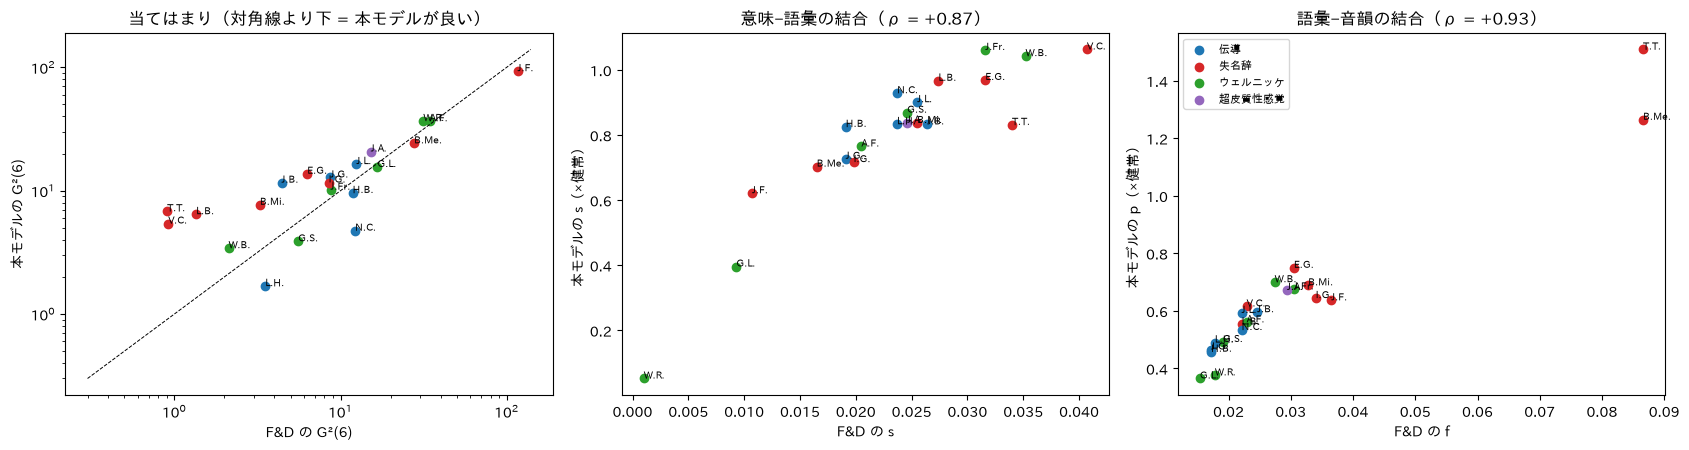

In [ ]:
# 図 2：F&D との比較
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for k, nm in enumerate(PATS):
    c_ = cols[CLIN[nm][0]]
    ax[0].scatter(gf[k], gm[k], color=c_); ax[0].annotate(nm, (gf[k], gm[k]), fontsize=7)
    ax[1].scatter(FD[nm][2], sv[k], color=c_); ax[1].annotate(nm, (FD[nm][2], sv[k]), fontsize=7)
    ax[2].scatter(FD[nm][3], pv_[k], color=c_); ax[2].annotate(nm, (FD[nm][3], pv_[k]), fontsize=7)
mx = max(gm.max(), gf.max()) * 1.2
ax[0].plot([0.3, mx], [0.3, mx], 'k--', lw=.7); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('F&D の G²(6)'); ax[0].set_ylabel('本モデルの G²(6)'); ax[0].set_title('当てはまり（対角線より下 = 本モデルが良い）')
ax[1].set_xlabel('F&D の s'); ax[1].set_ylabel('本モデルの s（×健常）'); ax[1].set_title(f'意味–語彙の結合（ρ = {spearmanr(sv, [FD[n][2] for n in PATS])[0]:+.2f}）')
ax[2].set_xlabel('F&D の f'); ax[2].set_ylabel('本モデルの p（×健常）'); ax[2].set_title(f'語彙–音韻の結合（ρ = {spearmanr(pv_, [FD[n][3] for n in PATS])[0]:+.2f}）')
for t, c_ in cols.items():
    ax[2].scatter([], [], color=c_, label=t)
ax[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig('2026_1030_final_compare.png', dpi=110); plt.show()

## 3. 回復実験（健常・LH・IG の推定値を真値に，$n=175$ を 12 回生成して推定し直す）

In [ ]:
gen = DellTanh('norm', 'none', n_mc=4000, noise_seed=999, a=A)
rng = np.random.default_rng(2030); R = 12; REC = {}
t0 = time.time()
for nm in ['control', 'L.H.', 'I.G.']:
    tr = H if nm == 'control' else P[nm]['th']
    q = norm6(pred(gen, tr)[0])
    n6 = int(round(counts(CTRL if nm == 'control' else DATA[nm])[:6].sum()))
    est = []
    for r_ in range(R):
        cb = np.append(rng.multinomial(n6, q), 0).astype(float)
        th, _ = de_fit(mS, cb, ['s', 'p'], {'sig': SIG0, 'theta': TH0}, maxiter=25, popsize=8, seed=r_)
        est.append([th['s'], th['p']])
    REC[nm] = (np.array([tr['s'], tr['p']]), np.array(est))
    print(f'{nm} 完了 ({time.time()-t0:.0f}s)')
print(f"\n{'':8s} | {'真値 s/σ':>9s} {'p/σ':>8s} | 中央値 推定/真値 (s, p) | 90%区間 log10(推定/真値)：s | p | corr(log s, log p)")
for nm, (t, e) in REC.items():
    lr = np.log10(e / t); q5, q95 = np.percentile(lr, [5, 95], 0)
    print(f"{nm:8s} | {t[0]/SIG0:9.2f} {t[1]/SIG0:8.1f} | {10**np.median(lr[:,0]):6.2f}, {10**np.median(lr[:,1]):6.2f}           | "
          f"[{q5[0]:+.2f},{q95[0]:+.2f}] | [{q5[1]:+.2f},{q95[1]:+.2f}] | {np.corrcoef(np.log(e).T)[0,1]:+.2f}")
psH = H['p'] / H['s']
for nm in ['L.H.', 'I.G.']:
    t, e = REC[nm]; v = (e[:, 1] / e[:, 0]) / psH
    print(f"{nm}: p/s（×健常） 真値 {(t[1]/t[0])/psH:.2f}  推定の 90% 区間 [{np.percentile(v,5):.2f}, {np.percentile(v,95):.2f}]")


## 4. 結論（2026-10-30 実行結果）

1. **健常**：6 カテゴリの条件付き $G^2=2.7$（自由度 3）。予測（正答 .976，意味 .013，形式 .006，混合 .003，無関連 .002，非単語 0）は実データとほぼ一致した。$s,\sigma$ を同時に $k$ 倍すると $k\le2.2$ では当てはまりが変わらず，$k=3.2$ から崩れる。この上端を単位 $\sigma_0=1.24\times10^{-4}$ とした。
2. **21 症例**：$G^2_6$ の合計は本モデル 353，F&D 333（W.R. を除くと 316 対 301）。中央値 11.6 対 8.7。本モデルが良い症例は 7/21，自由度 3 の 5% 臨界値以内の症例は 8/21 対 9/21。**F&D とほぼ同等の当てはまり**である。症例ごとのパラメータ数は同じ（$s,p$ の 2 つ）。
3. **推定値の対応**：$s$ と F&D の $s$ の順位相関 ρ = +0.87，$p$ と F&D の $f$ の順位相関 ρ = +0.93。$p/s$（健常比）の中央値は伝導 0.61 < ウェルニッケ 0.70 < 失名辞 0.86 で，失語型の並びは F&D の解釈と一致する。
4. **回復実験**：推定値の中央値は真値を回復した（推定/真値 = 0.98〜1.16）。ただし $s$ と $p$ は強く連動し（相関 −0.96〜−1.00），$s$ の 90% 区間は上側に長く伸びる（LH，IG で $\log_{10}$ +0.9〜+1.0）。$p/s$（健常比）の 90% 区間は LH [0.31, 0.65]，IG [0.39, 0.99] で**重なる**。群の傾向としての対比は保たれるが，**175 項目の 1 回の検査で個々の症例を伝導型か失名辞型かに分類する精度はない。**
5. **残る弱点**：軽度の失名辞失語（T.T. 6.8，V.C. 5.4，L.B. 6.4，E.G. 13.7。F&D はいずれも 6.3 以下）で F&D に劣る。
